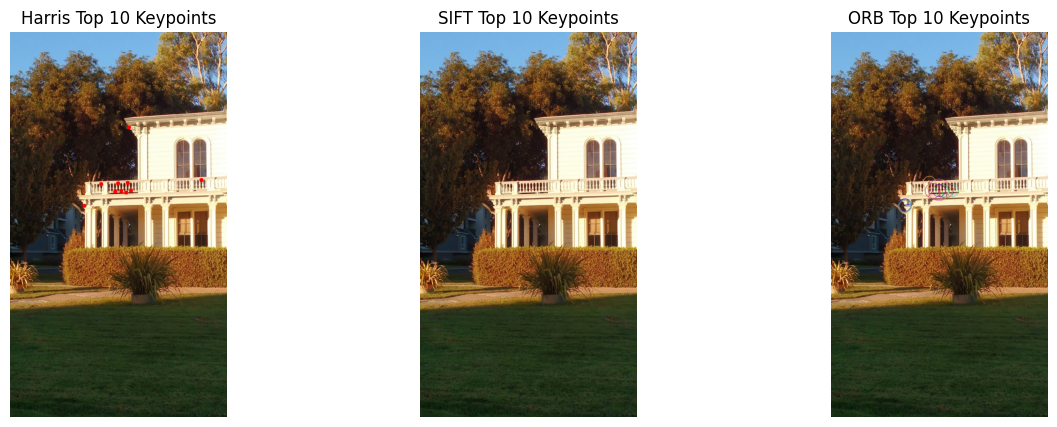

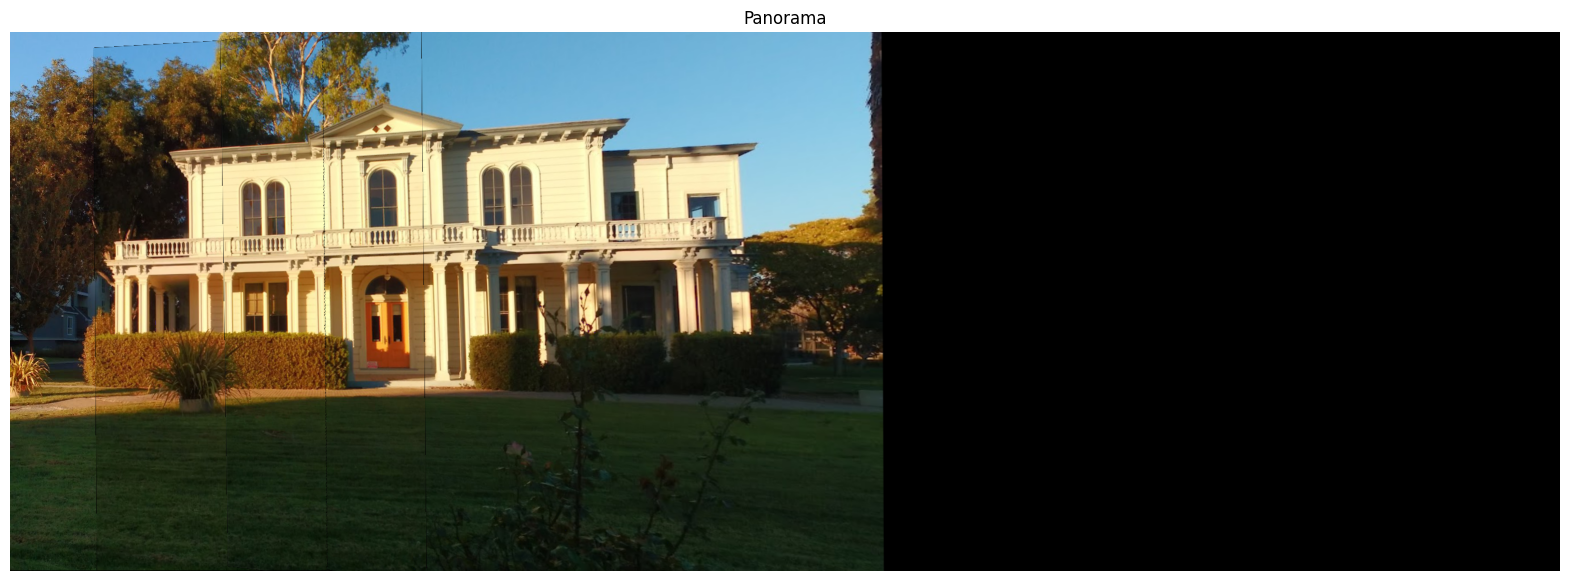

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('image1.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Harris Detector
corners = cv2.goodFeaturesToTrack(
    gray,
    maxCorners=10,
    qualityLevel=0.01,
    minDistance=10,
    useHarrisDetector=True
)

if corners is not None:
    corners = np.round(corners).astype(np.int32)
    harris_img = img.copy()
    for i in corners:
        x, y = i.ravel()
        cv2.circle(harris_img, (x, y), 5, (0, 0, 255), -1)

# SIFT
sift = cv2.SIFT_create()
keypoints_sift = sift.detect(gray, None)
keypoints_sift = sorted(keypoints_sift, key=lambda x: x.response, reverse=True)
top_keypoints_sift = keypoints_sift[:10]
sift_img = cv2.drawKeypoints(
    img.copy(),
    top_keypoints_sift,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

# ORB
orb = cv2.ORB_create(nfeatures=500)
keypoints_orb = orb.detect(gray, None)
keypoints_orb = sorted(keypoints_orb, key=lambda x: x.response, reverse=True)
top_keypoints_orb = keypoints_orb[:10]
orb_img = cv2.drawKeypoints(
    img.copy(),
    top_keypoints_orb,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(cv2.cvtColor(harris_img, cv2.COLOR_BGR2RGB))
axs[0].set_title('Harris Top 10 Keypoints')
axs[0].axis('off')
axs[1].imshow(cv2.cvtColor(sift_img, cv2.COLOR_BGR2RGB))
axs[1].set_title('SIFT Top 10 Keypoints')
axs[1].axis('off')
axs[2].imshow(cv2.cvtColor(orb_img, cv2.COLOR_BGR2RGB))
axs[2].set_title('ORB Top 10 Keypoints')
axs[2].axis('off')
plt.show()

images = [cv2.imread(f'image{i}.jpg') for i in range(1, 6)]

panorama = images[0]

# SIFT for feature extraction
sift = cv2.SIFT_create()

matcher = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

for i in range(1, len(images)):
    img_new = images[i]
    
    # Extract features
    kp1, des1 = sift.detectAndCompute(cv2.cvtColor(panorama, cv2.COLOR_BGR2GRAY), None)
    kp2, des2 = sift.detectAndCompute(cv2.cvtColor(img_new, cv2.COLOR_BGR2GRAY), None)
    
    # Matching with KNN k=2
    matches = matcher.knnMatch(des1, des2, k=2)
    
    # Ratio Test
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)
    
    if len(good_matches) < 4:
        print(f"Not enough matches for image {i+1}")
        continue
    
    # Extract points
    src_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    
    # Compute Homography with RANSAC
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    
    h, w = panorama.shape[:2]
    h_new, w_new = img_new.shape[:2]
    
    canvas_width = w + w_new
    canvas_height = max(h, h_new)
    
    warped_img = cv2.warpPerspective(img_new, H, (canvas_width, canvas_height))
    
    canvas = np.zeros((canvas_height, canvas_width, 3), dtype=np.uint8)
    canvas[0:h, 0:w] = panorama
    
    mask_warped = warped_img > 0
    canvas[mask_warped] = warped_img[mask_warped]
    
    # Update panorama
    panorama = canvas

plt.figure(figsize=(20, 10))
plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
plt.title('Panorama')
plt.axis('off')
plt.show()